In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
PROJECT_DIR = "/content/drive/MyDrive/FDL Project"
DATA_DIR = f"{PROJECT_DIR}/data/flower_photos"
SPLIT_DIR = f"{PROJECT_DIR}/data/splits"
MODEL_DIR = f"{PROJECT_DIR}/models"
SCRIPT_DIR = f"{PROJECT_DIR}/scripts"
PLOT_DIR = f"{PROJECT_DIR}/plots"
HISTORY_DIR = f"{PROJECT_DIR}/history"

In [ ]:
!pip install -q keras-hub

In [ ]:
import sys
import os
import json
import tensorflow as tf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime
from tensorflow import keras
from tensorflow.keras import mixed_precision
from tensorflow.keras.callbacks import EarlyStopping
import keras_hub


In [ ]:
import os

# Copy the entire "data" folder (images + splits), not just flower_photos.

LOCAL_PROJECT_DIR = "/content/local_project"
LOCAL_DATA_DIR = f"{LOCAL_PROJECT_DIR}/data"

if not os.path.exists(LOCAL_DATA_DIR):
    print("Copia dei dati in locale in corso...")
    os.makedirs(LOCAL_PROJECT_DIR, exist_ok=True)
    !cp -r "{PROJECT_DIR}/data" "{LOCAL_DATA_DIR}"
    print("Copia completata!")
else:
    print("Dati gia' presenti in locale, salto la copia.")




Copia dei dati in locale in corso...
Copia completata!


In [ ]:
!du -sh "{PROJECT_DIR}/data"

665M	/content/drive/MyDrive/FDL Project/data


In [ ]:
import os
print(os.path.exists(f"{LOCAL_PROJECT_DIR}/data/splits/train_folds.csv"))  # deve dare True
print(os.path.exists(f"{LOCAL_PROJECT_DIR}/data/flower_photos"))           # deve dare True

True
True


In [ ]:
if SCRIPT_DIR not in sys.path:
    sys.path.append(SCRIPT_DIR)

from preprocessing import load_common_datasets

## Mixed Precision (sfrutta i Tensor Core della T4)

In [ ]:
mixed_precision.set_global_policy('mixed_float16')
print(f"Compute dtype: {mixed_precision.global_policy().compute_dtype}")
print(f"Variable dtype: {mixed_precision.global_policy().variable_dtype}")

Compute dtype: float16
Variable dtype: float32


## Initialize Constants

### Model Version Legend
* 4.0 : Base Model w/ Data Augmentation
* 5.0 : Trained with new Resizing Image Logic
* 6.0 : Changes in the dataset
* 7.0 : train_file_name="train_folds_v2_distributed.csv"
* 8.0 : Trained with new Resizing Image Logic "bilinearity"
* 9.0 : train_file_name="train_folds_v3.csv"

In [ ]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
CURRENT_DATE = datetime.now().strftime("%Y-%m-%d_%H-%M-%S")

# TO DO : Change MODEL_NAME, MODEL_VERSION
MODEL_NAME = "ViT_FineTuned_Classifier"
MODEL_VERSION = "v9.0"
MODEL_FILE_NAME= f"{MODEL_NAME}_{MODEL_VERSION}"

In [ ]:
# Create a directory to save your models if it doesn't exist
os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(PLOT_DIR, exist_ok=True)
os.makedirs(HISTORY_DIR, exist_ok=True)

## Define Data Augmentation

In [ ]:
# TO DO : If needed, change this but must be changed in all notebooks
DATA_AUGMENTATION = keras.Sequential([
    keras.layers.RandomFlip("horizontal"),
    keras.layers.RandomRotation(0.1),
    keras.layers.RandomZoom(0.1),
    keras.layers.RandomContrast(0.1),
    keras.layers.RandomBrightness(0.2)
], name="data_augmentation_pipeline")

## Define Initialize model Function

In [ ]:
## Define Initialize Model Function

def initialize_model(num_classes=2, head_dropout=0.2,  freeze_backbone=True):


    backbone = keras_hub.models.Backbone.from_preset(
        "vit_base_patch16_224_imagenet"
    )
    preprocessor = keras_hub.models.ViTImageClassifierPreprocessor.from_preset(
        "vit_base_patch16_224_imagenet"
    )

    model = keras_hub.models.ViTImageClassifier(
        backbone=backbone,
        preprocessor=preprocessor,
        num_classes=num_classes,
        dropout=head_dropout,   # Dropout(0.2)
        activation=None,        # None = logits
        head_dtype="float32",
    )

    # Train backbone
    model.backbone.trainable = not freeze_backbone

    print(f"Backbone trainable: {model.backbone.trainable}")
    print(f"Backbone trainable weights: {len(model.backbone.trainable_weights)}")

    loss_fn = (
        keras.losses.SparseCategoricalCrossentropy(from_logits=True)
        if num_classes > 2
        else keras.losses.BinaryCrossentropy(from_logits=True)
    )

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-4),
        loss=loss_fn,
        metrics=['accuracy'],
    )

    return model



## Get Number of Folds

In [ ]:
df_main = pd.read_csv(f"{SPLIT_DIR}/train_folds.csv", dtype={'image_path': str, 'fold': int})
unique_folds = sorted(df_main['fold'].unique())
print(f"Found folds: {unique_folds}. \nStarting {len(unique_folds)}-Fold Cross Validation")

Found folds: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]. 
Starting 5-Fold Cross Validation


## Define Save Model Function

In [ ]:
def save_model(model, current_fold):
  model_name = f"{MODEL_FILE_NAME}_fold_{current_fold}_{CURRENT_DATE}.keras"
  save_path = os.path.join(MODEL_DIR, model_name)

  model.save(save_path)
  print(f"Saved model to: {save_path}")

## Model Training (with Cross Validaiton)

In [ ]:
all_fold_histories = []
WARMUP_EPOCHS = 15      # Stage 1: solo Head (backbone frozen)
FINE_TUNE_EPOCHS = 20   # Stage 2: Train Backbone at low  lr
NUM_FOLDS = len(unique_folds)

for current_fold in unique_folds:
    print(f"========== TRAINING FOLD {current_fold} / {NUM_FOLDS - 1} ==========")

    # PREPARE TRAIN AND VAL DATA HERE
    train_ds, val_ds, test_ds, class_names = load_common_datasets(
        project_dir=LOCAL_PROJECT_DIR,
        val_fold=current_fold,
        img_size=224,
        batch_size=32,
        normalization=None,
        train_file_name="train_folds_v3.csv"
    )

    num_classes = len(class_names)
    print(f"Detected {num_classes} classes: {class_names}")

    # AUGMENTATION
    train_ds = train_ds.map(
        lambda x, y: (DATA_AUGMENTATION(x, training=True), y),
        num_parallel_calls=tf.data.AUTOTUNE,
    ).prefetch(tf.data.AUTOTUNE)

    # Diagnostic first fold
    if current_fold == unique_folds[0]:
        from preprocessing import summarize_dataset
        summarize_dataset(train_ds, class_names=class_names, max_batches=1)

    # --------------------------------------------------------------------------
    # stage 1: FEATURE EXTRACTION (WARMUP HEAD, BACKBONE FROZEN)
    # --------------------------------------------------------------------------
    print("\n--- FASE 1: Addestramento Head (Backbone Frozen) ---")
    model = initialize_model(num_classes=num_classes, head_dropout=0.2, freeze_backbone=True)

    if current_fold == unique_folds[0]:
        model.summary()


    early_stopping_warmup = EarlyStopping(
        monitor='val_loss', patience=4, restore_best_weights=True, verbose=1
    )

    history_warmup = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=WARMUP_EPOCHS,
        callbacks=[early_stopping_warmup]
    )

    # --------------------------------------------------------------------------
    # stage 2: FINE-TUNING (UNFREEZE At low LR)
    # --------------------------------------------------------------------------
    print("\n--- FASE 2: Fine-Tuning (Sblocco Backbone a lr=1e-5) ---")
    model.backbone.trainable = True

    if current_fold == unique_folds[0]:
        model.summary()

    trainable = sum(keras.backend.count_params(w) for w in model.trainable_weights)
    print(f"Trainable params dopo unfreeze: {trainable:,}")

    model.summary()

    loss_fn = (
        keras.losses.SparseCategoricalCrossentropy(from_logits=True)
        if num_classes > 2
        else keras.losses.BinaryCrossentropy(from_logits=True)
    )


    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-5, clipnorm=1.0),
        loss=loss_fn,
        metrics=['accuracy']
    )

    early_stopping_ft = EarlyStopping(
        monitor='val_loss', patience=5, restore_best_weights=True, verbose=1
    )

    history_ft = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=FINE_TUNE_EPOCHS,
        callbacks=[early_stopping_ft]
    )

    # 3. combine history metrics and save
    combined_history = {}
    for k in history_warmup.history.keys():
        combined_history[k] = history_warmup.history[k] + history_ft.history[k]

    all_fold_histories.append(combined_history)
    save_model(model, current_fold)
    keras.backend.clear_session()

========== TRAINING FOLD 0 / 4 ==========
Detected 5 classes: ['class_0', 'class_1', 'class_2', 'class_3', 'class_4']
Dataset summary
------------------------------------------------------------
Number of classes: 5
Class names: ['class_0', 'class_1', 'class_2', 'class_3', 'class_4']

Batch 1
images.shape: (32, 224, 224, 3)
images.dtype: <dtype: 'float16'>
labels.shape: (32,)
labels.dtype: <dtype: 'int32'>
image min: 0.000
image max: 255.000
first labels: [4 4 0 0 3 0 3 3 4 1]
------------------------------------------------------------

--- FASE 1: Addestramento Head (Backbone Frozen) ---
Backbone trainable: False
Backbone trainable weights: 0


Preprocessor: "vi_t_image_classifier_preprocessor"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                                                  ┃                                   Config ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ vi_t_image_converter (ViTImageConverter)                      │                   Image size: (224, 224) │
└───────────────────────────────────────────────────────────────┴──────────────────────────────────────────┘

Model: "vi_t_image_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                                  ┃ Output Shape                       ┃             Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━┩
│ images (InputLayer)                           │ (None, 224, 224, 3)                │                   0 │
├───────────────────────────────────────────────┼────────────────────────────────────┼─────────────────────┤
│ vi_t_backbone (ViTBackbone)                   │ (None, 197, 768)                   │          85,798,656 │
├───────────────────────────────────────────────┼────────────────────────────────────┼─────────────────────┤
│ get_item (GetItem)                            │ (None, 768)                        │                   0 │
├───────────────────────────────────────────────┼────────────────────────────────────┼─────────────────────┤
│ output_dropout (Dropout)                      │ (None, 768)                        │                   0 │
├───────────────────────────────────────────────┼────────────────────────────────────┼─────────────────────┤
│ predictions (Dense)                           │ (None, 5)                          │               3,845 │
└───────────────────────────────────────────────┴────────────────────────────────────┴─────────────────────┘

 Total params: 85,802,501 (327.31 MB)

... (53 outputs left out)

 Trainable params: 85,802,501 (327.31 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 7,692 (30.05 KB)

Epoch 1/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 94s 580ms/step - accuracy: 0.9503 - loss: 0.1476 - val_accuracy: 0.9698 - val_loss: 0.0918
Epoch 2/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 10s 119ms/step - accuracy: 0.9747 - loss: 0.0784 - val_accuracy: 0.9734 - val_loss: 0.0826
Epoch 3/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 9s 118ms/step - accuracy: 0.9823 - loss: 0.0625 - val_accuracy: 0.9805 - val_loss: 0.0701
Epoch 4/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 9s 118ms/step - accuracy: 0.9885 - loss: 0.0385 - val_accuracy: 0.9805 - val_loss: 0.0610
Epoch 5/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 9s 117ms/step - accuracy: 0.9929 - loss: 0.0292 - val_accuracy: 0.9805 - val_loss: 0.0653
Epoch 6/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 9s 113ms/step - accuracy: 0.9965 - loss: 0.0199 - val_accuracy: 0.9822 - val_loss: 0.0615
Epoch 7/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 9s 119ms/step - accuracy: 0.9973 - loss: 0.0141 - val_accuracy: 0.9822 - val_loss: 0.0597
Epoch 8/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 10s 120ms/step - accuracy: 0.9978 - loss: 0.0122 - val_accuracy:

## Save Results

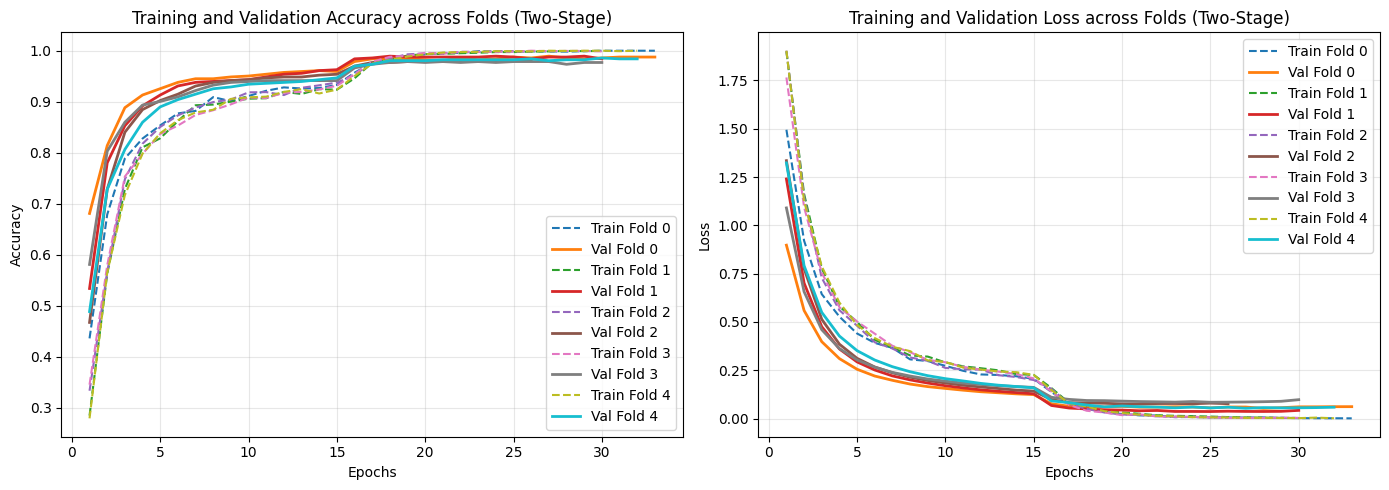

In [ ]:
def plot_cv_results(all_fold_histories):
    plt.figure(figsize=(14, 5))

    # PLOT 1: ACCURACY
    plt.subplot(1, 2, 1)
    for i, history in enumerate(all_fold_histories):
        epochs_range = range(1, len(history['accuracy']) + 1)
        plt.plot(epochs_range, history['accuracy'], label=f'Train Fold {i}', linestyle='--')
        plt.plot(epochs_range, history['val_accuracy'], label=f'Val Fold {i}', linewidth=2)
    plt.title('Training and Validation Accuracy across Folds (Two-Stage)')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend(loc='lower right')
    plt.grid(True, alpha=0.3)

    # PLOT 2: LOSS
    plt.subplot(1, 2, 2)
    for i, history in enumerate(all_fold_histories):
        epochs_range = range(1, len(history['loss']) + 1)
        plt.plot(epochs_range, history['loss'], label=f'Train Fold {i}', linestyle='--')
        plt.plot(epochs_range, history['val_loss'], label=f'Val Fold {i}', linewidth=2)
    plt.title('Training and Validation Loss across Folds (Two-Stage)')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend(loc='upper right')
    plt.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig(f"{PLOT_DIR}/{MODEL_FILE_NAME}.png", dpi=300, bbox_inches='tight')
    plt.show()

plot_cv_results(all_fold_histories)

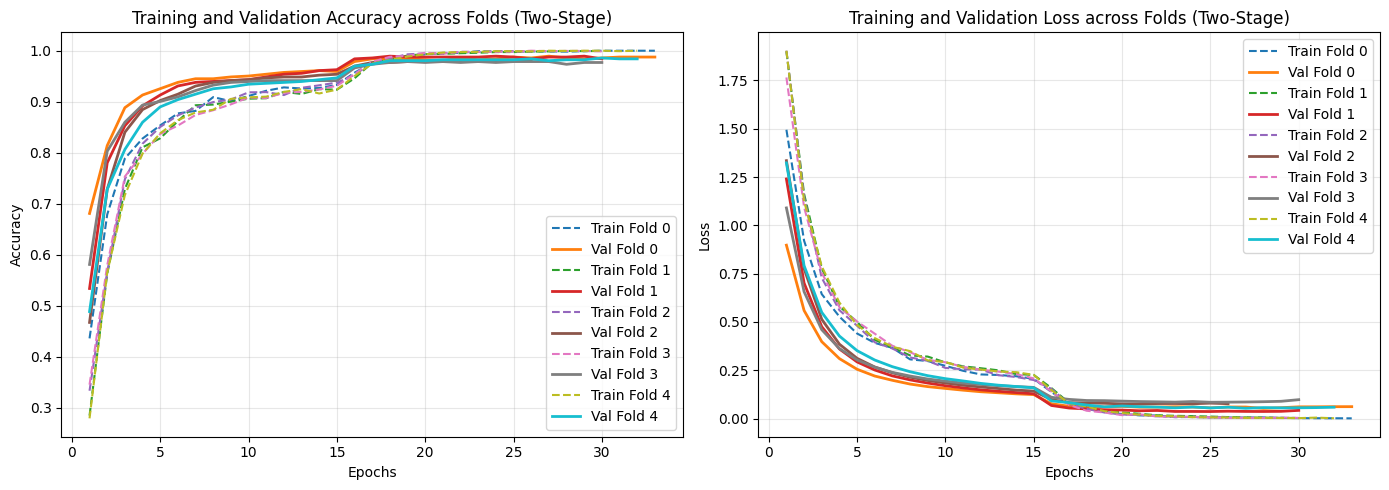

In [ ]:
plot_cv_results(all_fold_histories)

In [ ]:
def save_cv_history(all_fold_histories, filepath):
    def native_convert(obj):
        if isinstance(obj, np.ndarray):
            return obj.tolist()
        if isinstance(obj, (np.float32, np.float64)):
            return float(obj)
        if isinstance(obj, (np.int32, np.int64)):
            return int(obj)
        raise TypeError(f"Object of type {type(obj)} is not JSON serializable")

    with open(filepath, 'w') as f:
        json.dump(all_fold_histories, f, default=native_convert, indent=4)
    print(f"History successfully saved to {filepath}")

In [ ]:
save_cv_history(all_fold_histories, f"{HISTORY_DIR}/{MODEL_FILE_NAME}_history.json")

History successfully saved to /content/drive/MyDrive/FDL Project/history/ViT_FineTuned_Classifier_v9.0_history.json
